# 02 — Data Cleaning and Outlier Detection

Missing Values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate Rows: 0

Unique Machine failure values: [0 1]
Unique TWF values: [0 1]
Unique HDF values: [0 1]
Unique PWF values: [0 1]
Unique OSF values: [0 1]
Unique RNF values: [0 1]

Unique Type values: ['M' 'L' 'H']

Checking for negative values:
Negative values in Air temperature [K]: 0
Negative values in Process temperature [K]: 0
Negative values in Rotational speed [rpm]: 0
Negative values in Torque [Nm]: 0
Negative values in Tool wear [min]: 0

Basic Numeric Summary:
        Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
count  

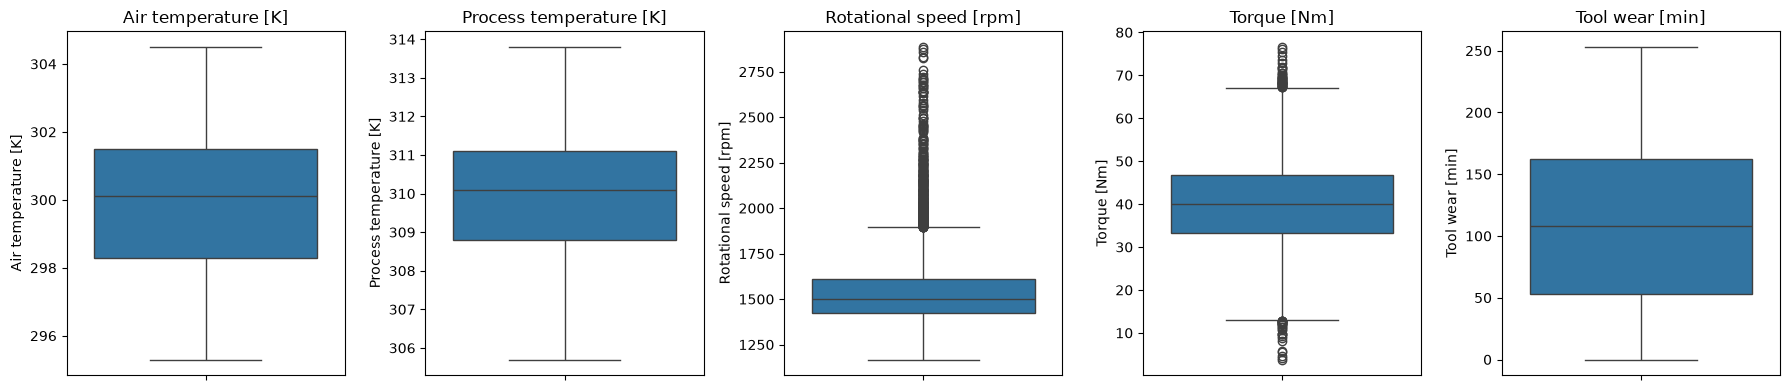


File exists check: True
Saved cleaned dataset successfully. Shape: (10000, 14)


In [1]:
import os
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Project Path Setup ---
# Determine project root reliably whether run from project root or notebooks folder
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)

RAW_FILE = PROJECT_ROOT / "data" / "raw" / "machine_failure.csv"
if not RAW_FILE.exists():
    raise FileNotFoundError(f"Raw dataset not found at '{RAW_FILE}'. Please verify the data directory.")

# 1. Load the raw dataset
df = pd.read_csv("data/raw/machine_failure.csv")

# 2. Check for missing values and duplicate rows
print("Missing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

# 3. Check unique values of target and categorical columns
print("\nUnique Machine failure values:", df["Machine failure"].unique())
for col in ["TWF", "HDF", "PWF", "OSF", "RNF"]:
    print(f"Unique {col} values:", df[col].unique())

print("\nUnique Type values:", df["Type"].unique())

# 4. Check for physically impossible negative values in numeric sensor columns
numeric_cols = [
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"
]

print("\nChecking for negative values:")
for col in numeric_cols:
    negatives = (df[col] < 0).sum()
    print(f"Negative values in {col}: {negatives}")

# 5. Basic numeric summary
print("\nBasic Numeric Summary:\n", df[numeric_cols].describe())

# 6. Check row identifier uniqueness
print("\nUDI is unique:", df["UDI"].is_unique)

# 7. Outlier Detection using the IQR (Interquartile Range) Method
print("\n--- Outlier Detection using IQR Method ---")
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]
    print(f"{col}: {len(outliers)} outliers (Lower Limit: {lower_limit:.2f}, Upper Limit: {upper_limit:.2f})")

# Simple boxplots for visual inspection of numeric distributions and outliers
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(18, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# 8. Important Outlier Rule:
# We do NOT automatically delete outliers. High rotational speed or torque readings
# represent real, extreme operating states rather than data errors.
# Removing them would discard valuable signals of machine stress and impending failure.

# 9. Create processed folder before saving
os.makedirs("data/processed", exist_ok=True)

# Save cleaned dataset
df.to_csv("data/processed/machine_failure_cleaned.csv", index=False)

# Verify the file was created and is accessible
file_created = os.path.exists("data/processed/machine_failure_cleaned.csv")
print("\nFile exists check:", file_created)
if not file_created:
    raise FileNotFoundError("Failed to create 'data/processed/machine_failure_cleaned.csv'.")
print("Saved cleaned dataset successfully. Shape:", df.shape)